| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../18_HPC_COMPUTACION_CIENTIFICA/18_3_Parallel_computing.ipynb) | [⏩](../19_SOFTWARE_CIENTIFICO/19_1_SOFTWARE_CIENTIFICO.ipynb) |

# 18.4 COMPUTACIÓN CIENTÍFICA

Computación científica conecta una pregunta física, un modelo matemático, un algoritmo y una evidencia numérica. Un solver que termina sin excepciones no garantiza una respuesta correcta; necesitamos referencias, análisis de error y una interpretación de los resultados.

Construiremos un experimento de Poisson con solución fabricada, estudiaremos matrices dispersas y compararemos solvers para una ODE rígida. Después distinguiremos error de discretización, aproximación y aprendizaje. Los casos sintéticos permiten comprobar cada paso sin descargar datos.

**Objetivos.** Organizar un cálculo fiable, verificar orden de convergencia, escoger estructuras numéricas y formular una comparación de costo y precisión. Requisitos: PDE, álgebra lineal y SciPy. Bibliotecas: NumPy, SciPy y Matplotlib.

## 1. La cadena de un resultado científico

Una pregunta como «¿qué temperatura alcanza una pieza?» requiere condiciones iniciales y de frontera, parámetros materiales y unidades. De ahí se define una PDE; la discretización convierte la ecuación en un problema algebraico; el solver produce una aproximación; las gráficas y las cantidades de interés permiten evaluar una afirmación.

Cada paso puede introducir error. Un parámetro físico mal estimado no se arregla refinando la malla; un solver impreciso no se arregla haciendo más datos con ese mismo solver. En SciML, un emulador se añade a esta cadena y necesita su propia evaluación.

## 2. Unidades y adimensionalización

Para calor $u_t=\alpha u_{xx}$, con $\alpha$ en $\mathrm{m}^2/\mathrm{s}$, una longitud $L$ define el tiempo característico $t_c=L^2/\alpha$. Escribiendo $\xi=x/L$ y $\tau=t/t_c$ obtenemos $u_\tau=u_{\xi\xi}$.

Adimensionalizar aclara escalas y puede mejorar la condición de una optimización. Si una pérdida suma residuos medidos en distintas unidades, sus pesos deben tener una interpretación: sumar «metros al cuadrado» y «kelvin al cuadrado» sin escalamiento arbitrario no expresa un objetivo físico claro.

La demostración de Poisson usará dominio y variables adimensionales. Es una elección explícita; para una aplicación real hay que reconstruir las unidades antes de interpretar el resultado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
from scipy.integrate import solve_ivp
from scipy.special import logsumexp
from time import perf_counter
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
L_m, alpha_m2_s = 0.1, 1.2e-5
print("Tiempo difusivo característico (s):", L_m**2/alpha_m2_s)

Tiempo difusivo característico (s): 833.3333333333335


## 3. Método de soluciones fabricadas

Para verificar $-u''=f$ en $(0,1)$ con $u(0)=u(1)=0$, elegimos primero
$$u_*(x)=\sin(\pi x)+0.1\sin(4\pi x).$$
Entonces
$$f(x)=\pi^2\sin(\pi x)+1.6\pi^2\sin(4\pi x).$$
La solución es conocida porque hemos construido el término fuente a partir de ella. Esto comprueba discretización y código para una función suave, pero no demuestra que el modelo físico sea adecuado para un material real. Esa segunda pregunta pertenece a validación con observaciones.

Con $n$ puntos interiores y $h=1/(n+1)$, la diferencia central produce una matriz tridiagonal con diagonal $2/h^2$ y sub/superdiagonal $-1/h^2$. Los extremos cero eliminan términos de frontera en el lado derecho.

Residual relativo algebraico: 5.77642950173833e-14
Error L2 discreto: 0.00016739547547326005 Error máximo: 0.0003168217498228376


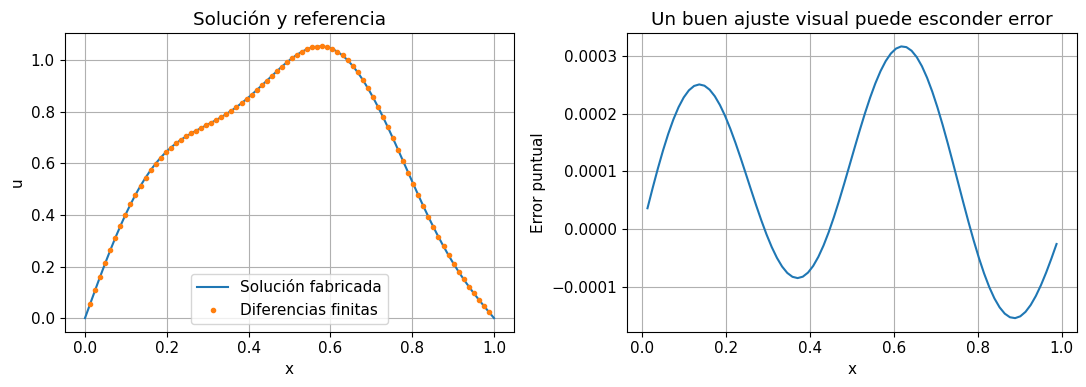

In [2]:
def exacta(x):
    return np.sin(np.pi*x)+0.1*np.sin(4*np.pi*x)

def fuente(x):
    return np.pi**2*np.sin(np.pi*x)+1.6*np.pi**2*np.sin(4*np.pi*x)

def poisson(n):
    h = 1/(n+1); x = h*np.arange(1, n+1)
    A = diags([-np.ones(n-1), 2*np.ones(n), -np.ones(n-1)], [-1, 0, 1], format="csc")/h**2
    b = fuente(x)
    u = spsolve(A, b)
    residual = np.linalg.norm(A @ u-b)/np.linalg.norm(b)
    error_l2 = np.sqrt(h*np.sum((u-exacta(x))**2))
    error_inf = np.max(np.abs(u-exacta(x)))
    return x, u, A, residual, error_l2, error_inf

x, u, A, residual, e2, einf = poisson(80)
print("Residual relativo algebraico:", residual)
print("Error L2 discreto:", e2, "Error máximo:", einf)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
xd = np.linspace(0, 1, 1000)
axes[0].plot(xd, exacta(xd), label="Solución fabricada")
axes[0].plot(x, u, ".", label="Diferencias finitas")
axes[0].set(xlabel="x", ylabel="u", title="Solución y referencia"); axes[0].legend()
axes[1].plot(x, u-exacta(x))
axes[1].set(xlabel="x", ylabel="Error puntual", title="Un buen ajuste visual puede esconder error")
plt.tight_layout(); plt.show()

## 4. Verificación por refinamiento

La expansión de Taylor de la diferencia central es
$$\frac{u(x-h)-2u(x)+u(x+h)}{h^2}=u''(x)+\frac{h^2}{12}u^{(4)}(x)+O(h^4).$$
Para una solución suficientemente suave y un problema estable esperamos error global de segundo orden. Estimaremos $p=\log(E(h)/E(h/2))/\log2$. Duplicaremos intervalos exactamente, usando $n=2^m-1$, para que cada paso sea la mitad del anterior.

Un residual algebraico minúsculo solo indica que resolvimos bien el sistema **discretizado**. Si $h$ es grande, ese sistema puede estar lejos de la PDE. Un refinamiento bien diseñado distingue esos dos errores.

Órdenes observados: [2.0250899  2.00617735 2.00153845 2.00038424 2.00009603]


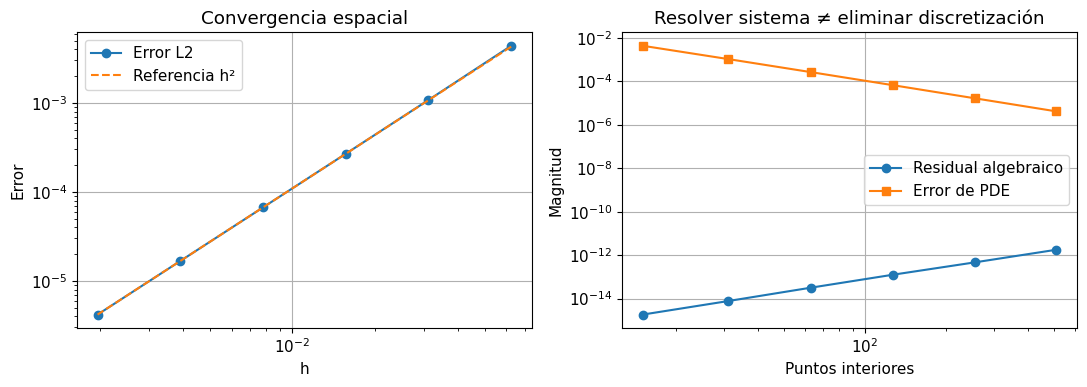

In [3]:
ns = 2**np.arange(4, 10)-1
hs, errores, residuales, tiempos = [], [], [], []
for n in ns:
    inicio = perf_counter()
    _, _, _, rr, err, _ = poisson(int(n))
    tiempos.append(perf_counter()-inicio)
    hs.append(1/(n+1)); errores.append(err); residuales.append(rr)
hs, errores = np.array(hs), np.array(errores)
orden = np.log(errores[:-1]/errores[1:])/np.log(2)
print("Órdenes observados:", orden)
assert orden[-1] > 1.9
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(hs, errores, "o-", label="Error L2")
axes[0].loglog(hs, errores[-1]*(hs/hs[-1])**2, "--", label="Referencia h²")
axes[0].set(xlabel="h", ylabel="Error", title="Convergencia espacial"); axes[0].legend()
axes[1].loglog(ns, residuales, "o-", label="Residual algebraico")
axes[1].loglog(ns, errores, "s-", label="Error de PDE")
axes[1].set(xlabel="Puntos interiores", ylabel="Magnitud", title="Resolver sistema ≠ eliminar discretización")
axes[1].legend(); plt.tight_layout(); plt.show()

## 5. Estructura dispersa y memoria

Una matriz densa de tamaño $n\times n$ requiere $n^2$ entradas. La tridiagonal solo tiene $3n-2$ valores no nulos, aunque el formato disperso guarda también índices. Esa estructura importa más que pequeñas optimizaciones de sintaxis.

En 2D o 3D, una factorización puede crear fill-in: nuevos valores no nulos en los factores aunque la matriz original sea dispersa. Por eso el costo no se deduce únicamente de `A.nnz`. Métodos iterativos y precondicionamiento pueden ser necesarios para mallas grandes.

El gráfico siguiente estima memoria de almacenamiento de una matriz, sin factorizarla ni reservar tamaños enormes. La imagen de la matriz muestra el patrón que se deriva del stencil.

Bytes reales de buffers CSC para n=80: 3180


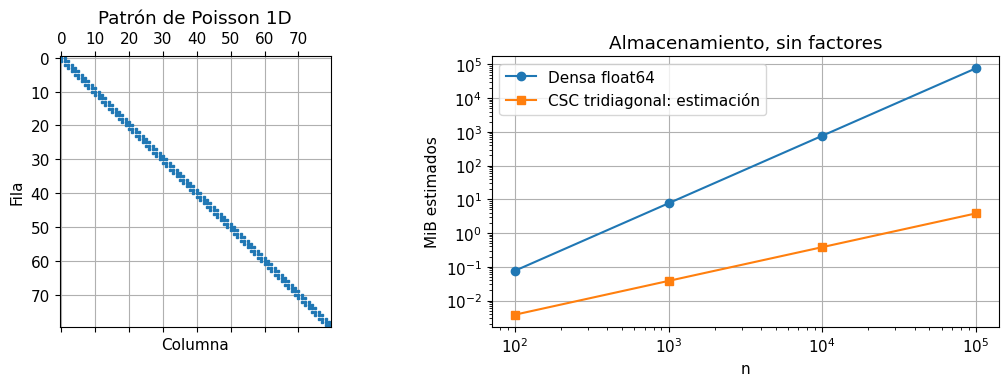

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].spy(A, markersize=2)
axes[0].set(title="Patrón de Poisson 1D", xlabel="Columna", ylabel="Fila")
Nmem = np.array([100, 1000, 10000, 100000], dtype=np.int64)
mem_densa = 8*Nmem.astype(float)**2
# Estimación CSC con valores float64 e índices int32.
mem_sparse = (3*Nmem-2)*(8+4)+(Nmem+1)*4
axes[1].loglog(Nmem, mem_densa/2**20, "o-", label="Densa float64")
axes[1].loglog(Nmem, mem_sparse/2**20, "s-", label="CSC tridiagonal: estimación")
axes[1].set(xlabel="n", ylabel="MiB estimados", title="Almacenamiento, sin factores")
axes[1].legend(); plt.tight_layout(); plt.show()
print("Bytes reales de buffers CSC para n=80:", A.data.nbytes+A.indices.nbytes+A.indptr.nbytes)

## 6. Condicionamiento y error de solución

La matriz de Poisson 1D tiene autovalores
$$\lambda_j=\frac4{h^2}\sin^2\left(\frac{j\pi}{2(n+1)}\right).$$
Su número de condición en norma dos crece aproximadamente como $O(h^{-2})$. Un refinamiento mejora la discretización pero puede amplificar error algebraico o redondeo. Una cota típica es $\|\delta u\|/\|u\|\lesssim\kappa(A)\|\delta b\|/\|b\|$ para perturbaciones pequeñas.

El valor de esa cota puede ser muy conservador; se usa para comprender sensibilidad, no para predecir exactamente el error observado. En FEM o problemas multiescala, elegir buen precondicionador puede decidir la viabilidad del cálculo.

## 7. Rigidez temporal: una solución lenta con escala rápida

Consideremos
$$u'=-\lambda(u-\cos t)-\sin t,\qquad u(0)=1.$$
La solución exacta es $u=\cos t$. Una perturbación $e$ satisface $e'=-\lambda e$, así que con $\lambda=1000$ existe una escala muy rápida aunque la solución observada varíe lentamente. Un método explícito necesita pasos pequeños por estabilidad; un método implícito puede manejar esa escala de otro modo.

Compararemos RK45 y Radau con las mismas tolerancias, intervalo y puntos de evaluación. Contaremos evaluaciones de la función, tiempo y error máximo; cada métrica dice algo distinto.

Método, nfev, segundos, error máximo:
('RK45', 8582, 0.1286187690020597, np.float64(6.291003139535789e-07))
('Radau', 136, 0.01707232899934752, np.float64(7.916977902922007e-05))


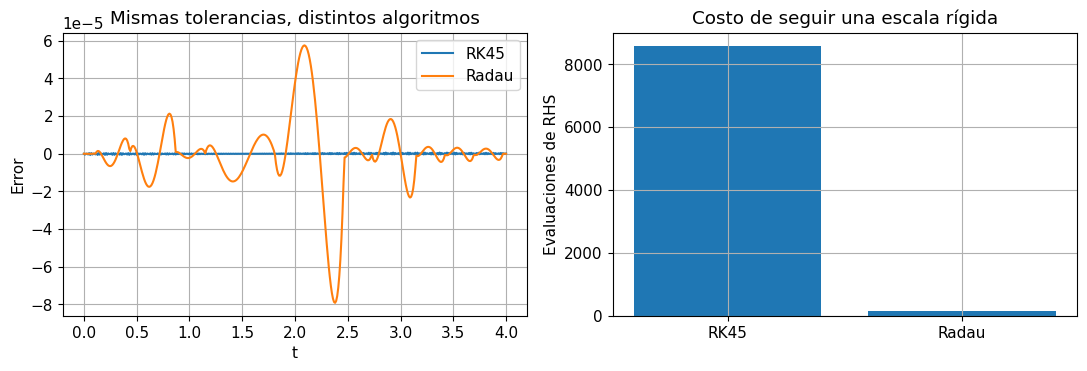

In [5]:
lam = 1000.0
t_eval = np.linspace(0, 4, 401)
def rhs(t, u):
    return -lam*(u-np.cos(t))-np.sin(t)

soluciones, resumen = {}, []
for metodo in ["RK45", "Radau"]:
    inicio = perf_counter()
    sol = solve_ivp(rhs, (0, 4), [1.0], method=metodo, rtol=1e-6, atol=1e-9, t_eval=t_eval)
    duracion = perf_counter()-inicio
    if not sol.success: raise RuntimeError(sol.message)
    error = np.max(np.abs(sol.y[0]-np.cos(t_eval)))
    resumen.append((metodo, sol.nfev, duracion, error))
    soluciones[metodo] = sol
print("Método, nfev, segundos, error máximo:")
for fila in resumen: print(fila)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for metodo, sol in soluciones.items():
    axes[0].plot(sol.t, sol.y[0]-np.cos(sol.t), label=metodo)
axes[0].set(xlabel="t", ylabel="Error", title="Mismas tolerancias, distintos algoritmos"); axes[0].legend()
axes[1].bar([r[0] for r in resumen], [r[1] for r in resumen])
axes[1].set(ylabel="Evaluaciones de RHS", title="Costo de seguir una escala rígida")
plt.tight_layout(); plt.show()

## 8. Qué significan las tolerancias

`rtol` y `atol` controlan una estimación de error local escalado por el solver; no prometen que el máximo error global sea exactamente `rtol`. La escala de las variables, el intervalo y la estabilidad importan. En sistemas, cada componente puede necesitar `atol` distinta.

Un método implícito resuelve problemas algebraicos internos, por lo que una evaluación de RHS no tiene el mismo costo en todos los métodos. Una comparación completa registra también factorizaciones, iteraciones y tiempo. En este ejemplo la rigidez es conocida, y la solución exacta facilita interpretar los resultados.

## 9. Formulaciones estables de una misma expresión

La matemática exacta puede ofrecer expresiones equivalentes con comportamientos numéricos distintos. Ya vimos cancelación; otra dificultad es overflow en exponenciales. Para $\log\sum_i e^{z_i}$, se usa
$$m+\log\sum_i e^{z_i-m},\qquad m=\max_i z_i.$$
Los argumentos desplazados no son positivos, lo que evita overflow. SciPy implementa esta operación como `logsumexp`. Resulta útil en posterior bayesiana, softmax y pérdidas de clasificación.

In [6]:
z = np.array([1000.0, 1001.0, 999.0])
with np.errstate(over="ignore"):
    ingenuo = np.log(np.sum(np.exp(z)))
m = z.max()
estable = m+np.log(np.sum(np.exp(z-m)))
print("Forma directa:", ingenuo)
print("Forma estable:", estable, "SciPy:", logsumexp(z))
assert np.allclose(estable, logsumexp(z))
h = 1e-12
print("exp(h)-1:", np.exp(h)-1, "expm1(h):", np.expm1(h))

Forma directa: inf
Forma estable: 1001.4076059644444 SciPy: 1001.4076059644444
exp(h)-1: 1.000088900582341e-12 expm1(h): 1.0000000000005e-12


## 10. Error total de un emulador científico

Si $G$ es el modelo continuo, $G_h$ el solver discretizado y $\widehat G$ el modelo aprendido, la desigualdad triangular da
$$\|G-\widehat G\|\le\underbrace{\|G-G_h\|}_{\text{discretización}}+\underbrace{\|G_h-\widehat G\|}_{\text{emulación}}.$$
A ello se suman discrepancia física, estimación de parámetros y ruido si se comparan observaciones. Una red que reproduce perfectamente un solver grueso puede conservar su sesgo.

Para ver esa separación, emularemos el enfriamiento en $t=2$ con un polinomio ajustado a datos de Euler. El conjunto de prueba cubrirá tasas nuevas. Compararemos error respecto al solver y respecto a la solución exacta.

RMSE discretización: 0.016955762283284385
RMSE emulación del solver: 4.168230531329423e-05
RMSE total frente al modelo exacto: 0.016959200547370854


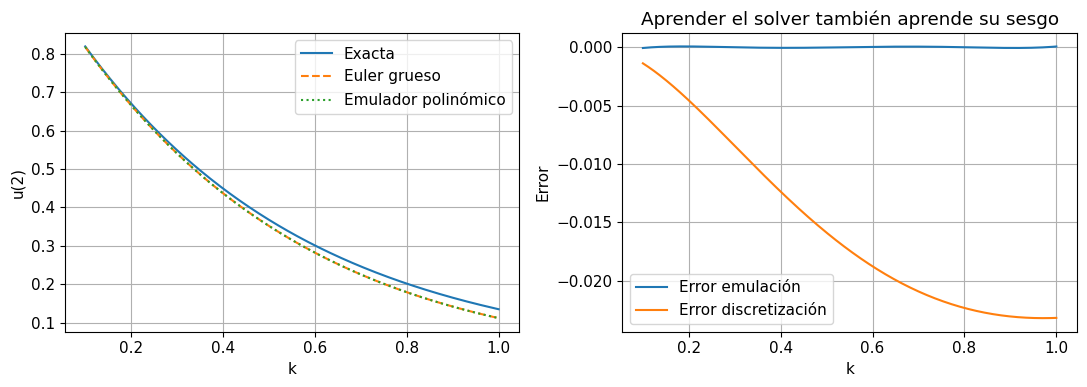

In [7]:
ktrain = np.linspace(0.1, 1.0, 18)
k_test = np.linspace(0.1, 1.0, 301)
T, Npasos = 2.0, 12
solver_train = (1-ktrain*T/Npasos)**Npasos
solver_test = (1-k_test*T/Npasos)**Npasos
coef = np.polynomial.polynomial.polyfit(ktrain, solver_train, deg=4)
emulador = np.polynomial.polynomial.polyval(k_test, coef)
verdad = np.exp(-k_test*T)
error_disc = np.sqrt(np.mean((solver_test-verdad)**2))
error_emul = np.sqrt(np.mean((emulador-solver_test)**2))
error_total = np.sqrt(np.mean((emulador-verdad)**2))
print("RMSE discretización:", error_disc)
print("RMSE emulación del solver:", error_emul)
print("RMSE total frente al modelo exacto:", error_total)
assert error_total <= error_disc+error_emul+1e-12
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_test, verdad, label="Exacta")
axes[0].plot(k_test, solver_test, "--", label="Euler grueso")
axes[0].plot(k_test, emulador, ":", label="Emulador polinómico")
axes[0].set(xlabel="k", ylabel="u(2)"); axes[0].legend()
axes[1].plot(k_test, emulador-solver_test, label="Error emulación")
axes[1].plot(k_test, solver_test-verdad, label="Error discretización")
axes[1].set(xlabel="k", ylabel="Error", title="Aprender el solver también aprende su sesgo")
axes[1].legend(); plt.tight_layout(); plt.show()

## 11. Verificación, validación y reproducibilidad

**Verificación:** ¿resolvemos correctamente las ecuaciones elegidas? Soluciones fabricadas, refinamiento y balances ayudan a responder. **Validación:** ¿esas ecuaciones describen el sistema real para el uso previsto? Requiere comparación con experimentos relevantes y sus incertidumbres. **Reproducibilidad:** ¿otra persona puede reconstruir el cálculo con entradas y entorno documentados?

Ninguna de las tres sustituye a las otras. Una simulación reproducible puede estar equivocada; un buen ajuste a un dataset puede ocultar bugs; una discretización convergente puede modelar un fenómeno inapropiado.

## 12. Escoger una cantidad de interés

No todos los errores importan igual. En ingeniería puede interesar flujo en una frontera, tiempo hasta un umbral, energía o tasa inferida. Una norma global pequeña no garantiza precisión en esa cantidad. Para una PINN, un residual bajo en puntos de colocación tampoco garantiza buen comportamiento en todo el dominio.

Define la cantidad de interés antes de ajustar, calcula su convergencia y usa una referencia que tenga precisión superior a la que deseas evaluar. Si una referencia comparte exactamente el mismo error que el método probado, la comparación puede dar una falsa sensación de acuerdo.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../18_HPC_COMPUTACION_CIENTIFICA/18_3_Parallel_computing.ipynb) | [⏩](../19_SOFTWARE_CIENTIFICO/19_1_SOFTWARE_CIENTIFICO.ipynb) |